In [1]:
# Import all required libraries
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Define Hyperparameters
IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32
EPOCHS = 25
LEARNING_RATE = 0.001
NUM_CLASSES = 6

# Since you launched Jupyter directly inside the train folder
TRAIN_DIR = '.' 

# 2. Configure Data Augmentation with 20% Validation Split
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2  # Automatically splits 20% data for validation
)

# 3. Setup Data Generators
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'     # Uses 80% data for training
)

val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'   # Uses 20% data for validation
)

Found 7566 images belonging to 7 classes.
Found 1887 images belonging to 7 classes.


In [2]:
# 1. Update NUM_CLASSES based on your dataset output
NUM_CLASSES = 7

# 2. Build the Sequential CNN Model
model = models.Sequential([
    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3), name='conv2d'),
    layers.MaxPooling2D((2, 2), name='max_pooling2d'),
    
    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu', name='conv2d_1'),
    layers.MaxPooling2D((2, 2), name='max_pooling2d_1'),
    
    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu', name='conv2d_2'),
    layers.MaxPooling2D((2, 2), name='max_pooling2d_2'),
    
    # Fully Connected Layers
    layers.Flatten(name='flatten'),
    layers.Dense(128, activation='relu', name='dense'),
    layers.Dropout(0.5, name='dropout'),
    layers.Dense(NUM_CLASSES, activation='softmax', name='dense_1')
])

# 3. Compile the Model
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Define Callbacks for Optimal Training
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_fruit_model.h5', monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)
]

# 5. Train the Model
history = model.fit(
    train_generator,
    epochs=25,
    validation_data=val_generator,
    callbacks=callbacks
)

C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 816ms/step - accuracy: 0.6110 - loss: 1.0445
Epoch 1: val_loss improved from None to 0.55136, saving model to best_fruit_model.h5



Epoch 1: finished saving model to best_fruit_model.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 237s 989ms/step - accuracy: 0.6110 - loss: 1.0445 - val_accuracy: 0.8119 - val_loss: 0.5514 - learning_rate: 0.0010
Epoch 2/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.7794 - loss: 0.6235
Epoch 2: val_loss improved from 0.55136 to 0.42148, saving model to best_fruit_model.h5



Epoch 2: finished saving model to best_fruit_model.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 116s 489ms/step - accuracy: 0.7794 - loss: 0.6235 - val_accuracy: 0.8479 - val_loss: 0.4215 - learning_rate: 0.0010
Epoch 3/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.8121 - loss: 0.5424
Epoch 3: val_loss improved from 0.42148 to 0.41030, saving model to best_fruit_model.h5



Epoch 3: finished saving model to best_fruit_model.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 128s 539ms/step - accuracy: 0.8121 - loss: 0.5424 - val_accuracy: 0.8516 - val_loss: 0.4103 - learning_rate: 0.0010
Epoch 4/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.8320 - loss: 0.4672
Epoch 4: val_loss improved from 0.41030 to 0.31419, saving model to best_fruit_model.h5


...


Epoch 19: finished saving model to best_fruit_model.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 129s 544ms/step - accuracy: 0.9455 - loss: 0.1487 - val_accuracy: 0.9608 - val_loss: 0.1085 - learning_rate: 2.0000e-04
Epoch 20/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.9537 - loss: 0.1210
Epoch 20: val_loss improved from 0.10851 to 0.08264, saving model to best_fruit_model.h5



Epoch 20: finished saving model to best_fruit_model.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 125s 526ms/step - accuracy: 0.9537 - loss: 0.1210 - val_accuracy: 0.9650 - val_loss: 0.0826 - learning_rate: 2.0000e-04
Epoch 21/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 450ms/step - accuracy: 0.9535 - loss: 0.1287
Epoch 21: val_loss improved from 0.08264 to 0.08022, saving model to best_fruit_model.h5



Epoch 21: finished saving model to best_fruit_model.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 126s 532ms/step - accuracy: 0.9535 - loss: 0.1287 - val_accuracy: 0.9703 - val_loss: 0.0802 - learning_rate: 2.0000e-04
Epoch 22/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step - accuracy: 0.9569 - loss: 0.1173
Epoch 22: val_loss improved from 0.08022 to 0.07594, saving model to best_fruit_model.h5



Epoch 22: finished saving model to best_fruit_model.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 130s 548ms/step - accuracy: 0.9569 - loss: 0.1173 - val_accuracy: 0.9687 - val_loss: 0.0759 - learning_rate: 2.0000e-04
Epoch 23/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.9578 - loss: 0.1144
Epoch 23: val_loss did not improve from 0.07594
237/237 ━━━━━━━━━━━━━━━━━━━━ 133s 561ms/step - accuracy: 0.9578 - loss: 0.1144 - val_accuracy: 0.9693 - val_loss: 0.0768 - learning_rate: 2.0000e-04
Epoch 24/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 501ms/step - accuracy: 0.9555 - loss: 0.1194
Epoch 24: val_loss did not improve from 0.07594
237/237 ━━━━━━━━━━━━━━━━━━━━ 138s 585ms/step - accuracy: 0.9555 - loss: 0.1194 - val_accuracy: 0.9709 - val_loss: 0.0891 - learning_rate: 2.0000e-04
Epoch 25/25
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.9630 - loss: 0.1069
Epoch 25: val_loss improved from 0.07594 to 0.07257, saving model to best_fruit_model.h5



Epoch 25: finished saving model to best_fruit_model.h5
237/237 ━━━━━━━━━━━━━━━━━━━━ 133s 561ms/step - accuracy: 0.9630 - loss: 0.1069 - val_accuracy: 0.9724 - val_loss: 0.0726 - learning_rate: 2.0000e-04
Restoring model weights from the end of the best epoch: 25.


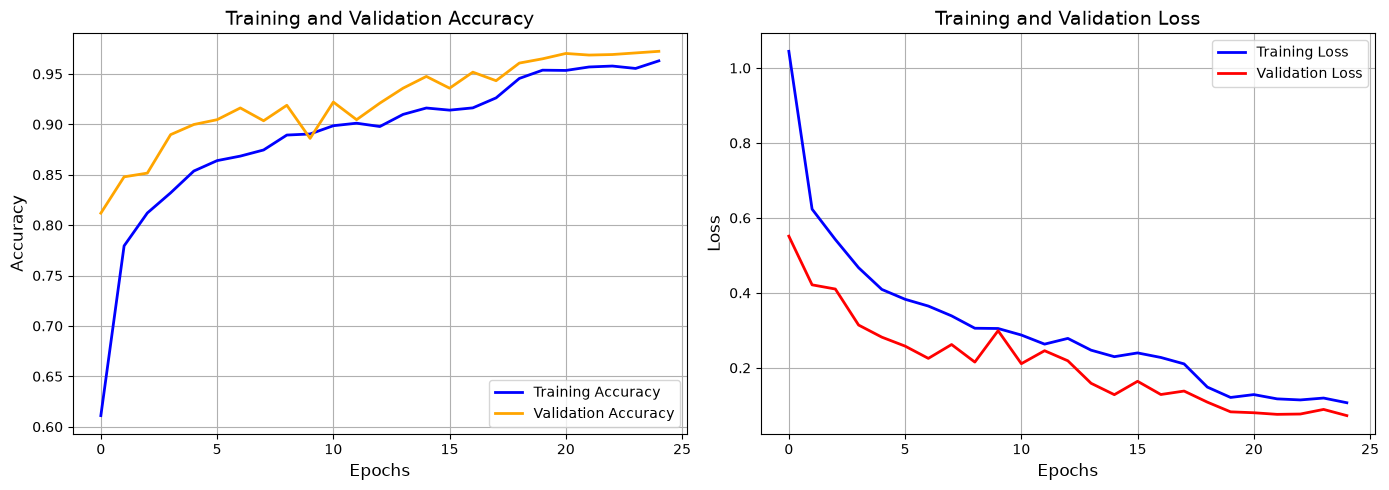

In [3]:
# Plot Training & Validation Accuracy and Loss Curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(14, 5))

# Plot 1: Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True)

# Plot 2: Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='blue', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='red', linewidth=2)
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()


In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# 1. Saved Model Load Karein
model_path = 'best_fruit_model.h5'
model = load_model(model_path)
print("Model Successfully Loaded!")

# 2. Class Labels Define Karein (Apne dataset ke folder names ke hisab se order set karein)
class_labels = ['Fresh Apple', 'Fresh Banana', 'Fresh Orange', 'Rotten Apple', 'Rotten Banana', 'Rotten Orange']

def predict_fruit_freshness(img_path):
    # Image Load aur Preprocess karna (150x150 Target Size)
    img = image.load_img(img_path, target_size=(150, 150))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0  # Normalization

    # Model Prediction
    predictions = model.predict(img_array)[0]
    predicted_class_idx = np.argmax(predictions)
    predicted_label = class_labels[predicted_class_idx]
    confidence = predictions[predicted_class_idx] * 100

    # Freshness Score Logic
    if 'Fresh' in predicted_label:
        freshness_score = confidence
        status = "FRESH"
    else:
        freshness_score = 100 - confidence
        status = "ROTTEN"

    # Display Result
    plt.imshow(image.load_img("D:\fruite_freshness_detection\dataset\apple .jpeg"))
    plt.axis('off')
    plt.title(f"Prediction: {predicted_label}\nFreshness Score: {freshness_score:.2f}% ({status})", 
              fontsize=14, color='green' if status == "FRESH" else 'red')
    plt.show()

    return predicted_label, freshness_score

# 3. Nayi Image Par Test Karein (Yahan apni test image ka path dalein)
# predict_fruit_freshness('test_image.jpg')

<>:37: SyntaxWarning: invalid escape sequence '\d'
<>:37: SyntaxWarning: invalid escape sequence '\d'
C:\Users\DELL\AppData\Local\Temp\ipykernel_26536\2997170282.py:37: SyntaxWarning: invalid escape sequence '\d'
  plt.imshow(image.load_img("D:\fruite_freshness_detection\dataset\apple .jpeg"))


Model Successfully Loaded!


In [8]:
# Function call karne ke liye ye run karein:
# Path ke aage 'r' lagaya hai taaki SyntaxWarning na aaye
predict_fruit_freshness("D:\fruite_freshness_detection\dataset\apple .jpeg")

<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
C:\Users\DELL\AppData\Local\Temp\ipykernel_26536\2330545423.py:3: SyntaxWarning: invalid escape sequence '\d'
  predict_fruit_freshness("D:\fruite_freshness_detection\dataset\apple .jpeg")


OSError: [Errno 22] Invalid argument: 'D:\x0cruite_freshness_detection\\dataset\x07pple .jpeg'